In [1]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# Connect and Access Git Repository

import os
import sys
import json
from getpass import getpass
from pathlib import Path

GITHUB_USERNAME = "sharaffatima"
REPO_NAME = "bachelor-thesis"



token = getpass("GitHub token: ")


REPO_URL = f"https://{token}@github.com/{GITHUB_USERNAME}/{REPO_NAME}.git"
REPO_DIR = Path("/content") / REPO_NAME


if not REPO_DIR.exists():
    !git clone {REPO_URL} {REPO_DIR}
else:
    %cd {REPO_DIR}
    !git pull

%cd {REPO_DIR}
sys.path.append(str(REPO_DIR))

print("Repo exists:", REPO_DIR.exists())

GitHub token: ··········
/content/bachelor-thesis
remote: Enumerating objects: 7, done.
remote: Counting objects: 100% (7/7), done.
remote: Compressing objects: 100% (1/1), done.
remote: Total 4 (delta 3), reused 4 (delta 3), pack-reused 0 (from 0)
Unpacking objects: 100% (4/4), 514 bytes | 514.00 KiB/s, done.
From https://github.com/sharaffatima/bachelor-thesis
   41f7168..ecbe488  main       -> origin/main
Updating 41f7168..ecbe488
Fast-forward
 explainability/evaluation.py | 34 ++++++++++++----------------------
 1 file changed, 12 insertions(+), 22 deletions(-)
/content/bachelor-thesis
Repo exists: True


In [3]:
# Imports
import os
import numpy as np
import torch
from torch.utils.data import DataLoader

# global configuration

REPO_DIR = Path("/content/bachelor-thesis")
sys.path.append(str(REPO_DIR))


from utils.dataset import PTBXLAnoFormerDataset
from explainability.attention import AnoFormerExplainability
from utils.seed import set_seed, RANDOM_SEED
from models.anoformer import AnoFormerMainModel
from utils.anomaly_threshold import ChooseThresholdForRecall
from explainability.evaluation import plot_temporal_importance

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
set_seed(RANDOM_SEED)
print(f"Active device: {DEVICE}")

Active device: cuda


In [4]:
# Paths to Directories

DATA_DIR = Path("/content/drive/MyDrive/ECG data")
PROCESSED_DIR = DATA_DIR / "processed"
RESULTS_DIR = DATA_DIR / "results"

MODEL_DIR = RESULTS_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

ANOFORMER_MODEL_DIR = MODEL_DIR / "anoformer"
ANOFORMER_MODEL_DIR.mkdir(parents=True, exist_ok=True)

ANOFORMER_MODEL_PATH = ANOFORMER_MODEL_DIR / "anoformer_40epochs_larger_capacity_2.pt"

print("MODEL_DIR:", ANOFORMER_MODEL_DIR)
print("MODEL_PATH:", ANOFORMER_MODEL_PATH)

MODEL_DIR: /content/drive/MyDrive/ECG data/results/models/anoformer
MODEL_PATH: /content/drive/MyDrive/ECG data/results/models/anoformer/anoformer_40epochs_larger_capacity_2.pt


In [5]:
# Load my preprocessed data

X_train = np.load(PROCESSED_DIR / "X_train.npy")
y_train = np.load(PROCESSED_DIR / "y_train.npy")

X_val = np.load(PROCESSED_DIR / "X_val.npy")
y_val = np.load(PROCESSED_DIR / "y_val.npy")

X_test = np.load(PROCESSED_DIR / "X_test.npy")
y_test = np.load(PROCESSED_DIR / "y_test.npy")

print(X_train.shape, y_train.shape)
print(X_val.shape, y_val.shape)
print(X_test.shape, y_test.shape)

(17418, 1000, 12) (17418,)
(2183, 1000, 12) (2183,)
(2198, 1000, 12) (2198,)


In [6]:
# Training only on normal data

normal_train_mask = y_train == 0

X_train_normal = X_train[normal_train_mask]
y_train_normal = y_train[normal_train_mask]

print("Training on normal ECGs:", X_train_normal.shape)

Training on normal ECGs: (7596, 1000, 12)


In [7]:
# Datasets

train_dataset = PTBXLAnoFormerDataset(
    X_train_normal,
    y_train_normal,
    normalize=True
)

val_dataset = PTBXLAnoFormerDataset(
    X_val,
    y_val,
    mean=train_dataset.mean,
    std=train_dataset.std,
    normalize=True
)

test_dataset = PTBXLAnoFormerDataset(
    X_test,
    y_test,
    mean=train_dataset.mean,
    std=train_dataset.std,
    normalize=True
)

In [8]:
# Dataloaders

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    drop_last=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [9]:
# Check the shapes

# Expected:
#         Batch X: torch.Size([4, 1000, 12])
#         Batch y: torch.Size([4])

batch_x, batch_y = next(iter(train_loader))

print(batch_x.shape)
print(batch_y.shape)

torch.Size([4, 1000, 12])
torch.Size([4])


In [10]:
# Create Model

AnoFormer = AnoFormerMainModel(
    NumFeatures=12,
    ModelDimension=64,
    NumHeads=4,
    NumEncoderLayers=2,
    NumDecoderLayers=2,
    DiscriminatorLayers=1,
    ForwardDimension=128,
    DropoutRate=0.1,
    GeneratorLearningRate=1e-4,
    DiscriminatorLearningRate=1e-4,
    MaskingRate=0.15,
    AnomalyThreshold=0.75,
    ReconstructionWeight=10.0,
)

In [11]:
# Test

batch_x, _ = next(iter(train_loader))
batch_x = batch_x.to(AnoFormer.Device)

with torch.no_grad():
    masked_x, _ = AnoFormer.Masking(batch_x, None)
    reconstruction = AnoFormer.Generator(masked_x)

print("Input:", batch_x.shape)
print("Masked:", masked_x.shape)
print("Reconstruction:", reconstruction.shape)

Input: torch.Size([4, 1000, 12])
Masked: torch.Size([4, 1000, 12])
Reconstruction: torch.Size([4, 1000, 12])


In [14]:
# Instead of retraining, I can just reload the saved model and use directly for anomaly detection and evaluation etc... no need to run the Training cell

#ANOFORMER_MODEL_PATH = ANOFORMER_MODEL_DIR / "anoformer_20epochs.pt"
#ANOFORMER_MODEL_PATH = ANOFORMER_MODEL_DIR / "anoformer_40epochs.pt"
#ANOFORMER_MODEL_PATH = ANOFORMER_MODEL_DIR / "anoformer_80epochs.pt"
#ANOFORMER_MODEL_PATH = ANOFORMER_MODEL_DIR / "anoformer_40epochs_larger_capacity.pt"
ANOFORMER_MODEL_PATH = ANOFORMER_MODEL_DIR / "anoformer_40epochs_larger_capacity_2.pt"

AnoFormer.Load(str(ANOFORMER_MODEL_PATH))

Modell geladen von: /content/drive/MyDrive/ECG data/results/models/anoformer/anoformer_40epochs_larger_capacity_2.pt


In [13]:
AnoFormer.AnomalyLimit = None

In [ ]:
# Training

print("\n── AnoFormer Training starts ─────────────────────────────")

AnoFormer.TrainModel(
    TrainingLoader=train_loader,
    NumEpochs=40,
    PrintInterval=1,
)


── AnoFormer Training starts ─────────────────────────────
Epoche    1/40 | G-Total=5.9380 | G-GAN=1.0571 | G-Rec=0.4881 | D=0.5635
Epoche    2/40 | G-Total=11.2198 | G-GAN=1.7221 | G-Rec=0.9498 | D=0.4224
Epoche    3/40 | G-Total=4.3651 | G-GAN=0.7853 | G-Rec=0.3580 | D=0.6831
Epoche    4/40 | G-Total=11.0383 | G-GAN=1.4788 | G-Rec=0.9559 | D=0.4579
Epoche    5/40 | G-Total=3.9166 | G-GAN=0.7497 | G-Rec=0.3167 | D=0.6889
Epoche    6/40 | G-Total=10.7257 | G-GAN=1.5874 | G-Rec=0.9138 | D=0.4286
Epoche    7/40 | G-Total=3.6806 | G-GAN=0.7300 | G-Rec=0.2951 | D=0.7074
Epoche    8/40 | G-Total=10.6523 | G-GAN=1.6484 | G-Rec=0.9004 | D=0.4290
Epoche    9/40 | G-Total=3.4868 | G-GAN=0.7287 | G-Rec=0.2758 | D=0.7050
Epoche   10/40 | G-Total=10.4928 | G-GAN=1.6536 | G-Rec=0.8839 | D=0.4313
Epoche   11/40 | G-Total=3.3739 | G-GAN=0.7258 | G-Rec=0.2648 | D=0.7066
Epoche   12/40 | G-Total=10.1029 | G-GAN=1.5840 | G-Rec=0.8519 | D=0.4341
Epoche   13/40 | G-Total=3.2430 | G-GAN=0.7189 | G-Rec=0.2

In [ ]:
# Save the Model after training

print("\n── Saving AnoFormer ──────────────────────────────────────")

AnoFormer.Save(str(ANOFORMER_MODEL_PATH))


── Saving AnoFormer ──────────────────────────────────────
Modell gespeichert unter: /content/drive/MyDrive/ECG data/results/models/anoformer_40epochs_larger_capacity_2.pt


In [ ]:
# Calculate stable anomaly scores for the validation set

ValidationScores = AnoFormer.CalculateScores(
    DataLoaderObject=val_loader,
    NumMaskRuns=5,
    Seed=42,
)

ValidationLabels = np.asarray(y_val).astype(int).reshape(-1)

print("Validation scores shape:", ValidationScores.shape,)
print("Validation labels shape:", ValidationLabels.shape,)
print("Normal validation records:", (ValidationLabels == 0).sum(),)
print("Anomalous validation records:", (ValidationLabels == 1).sum(),)
print("Mean normal score:", ValidationScores[ValidationLabels == 0].mean(),)
print("Mean anomalous score:", ValidationScores[ValidationLabels == 1].mean(),)

Validation scores shape: (2183,)
Validation labels shape: (2183,)
Normal validation records: 955
Anomalous validation records: 1228
Mean normal score: 0.22697824
Mean anomalous score: 0.4549361


In [ ]:
# choose Threshold based on minimum TargetRecall

ThresholdResult = ChooseThresholdForRecall(
    Labels=ValidationLabels,
    Scores=ValidationScores,
    TargetRecall=0.80,
)

ChosenThreshold = ThresholdResult["Threshold"]

print("Chosen threshold:", ChosenThreshold)
print("Validation precision:", ThresholdResult["Precision"])
print("Validation recall:", ThresholdResult["Recall"])

Chosen threshold: 0.17710630595684052
Validation precision: 0.5960024227740763
Validation recall: 0.8013029315960912


In [ ]:
# Anomaly detection

print("\n── AnoFormer Anomaly Detection ───────────────────────────")

TestScores, TestPredictions = AnoFormer.DetectAnomalies(
    TestLoader=test_loader,
    Threshold=ChosenThreshold,
    NumMaskRuns=5,
    Seed=42,
)

TestLabels = np.asarray(y_test).astype(int).reshape(-1)

print("Test scores shape:", TestScores.shape)
print("Test predictions shape:", TestPredictions.shape)
print("Detected anomalous ECG records:", TestPredictions.sum())
print("Validation-derived threshold:", AnoFormer.AnomalyLimit)


── AnoFormer Anomaly Detection ───────────────────────────
Test scores shape: (2198,)
Test predictions shape: (2198,)
Detected anomalous ECG records: 1663
Validation-derived threshold: 0.17710630595684052


In [ ]:
# Evaluation

print("\n── AnoFormer Evaluation ───────────────────────────")

TestLabels = np.asarray(y_test).astype(int).reshape(-1)

Metrics = AnoFormer.Evaluate(
    TrueLabels=TestLabels,
    Scores=TestScores,
    PredictedLabels=TestPredictions,
)


── AnoFormer Evaluation ───────────────────────────
  Accuracy            : 0.5851
  Precision           : 0.5971
  Recall              : 0.804
  F1Score             : 0.6853
  FalseNegativeRate   : 0.196
  Threshold           : 0.177106
  TruePositive        : 993
  TrueNegative        : 293
  FalsePositive       : 670
  FalseNegative       : 242
  ROC_AUC             : 0.6463
  PR_AUC              : 0.7303
  ConfusionMatrix
    : [[293 670]
 [242 993]]


In [ ]:
# Save AnoFormer test outputs for shared sample selection

EVALUATION_DIR = RESULTS_DIR / "evaluation"
EVALUATION_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

AnoFormerOutputPath = (
    EVALUATION_DIR
    / "anoformer_test_outputs.npz"
)

np.savez_compressed(
    AnoFormerOutputPath,

    scores=np.asarray(
        TestScores,
        dtype=np.float32,
    ),

    predictions=np.asarray(
        TestPredictions,
        dtype=np.int64,
    ),

    labels=np.asarray(
        TestLabels,
        dtype=np.int64,
    ),

    threshold=np.asarray(
        ChosenThreshold,
        dtype=np.float32,
    ),
)

print(
    "Saved AnoFormer test outputs to:",
    AnoFormerOutputPath,
)

Saved AnoFormer test outputs to: /content/drive/MyDrive/ECG data/results/evaluation/anoformer_test_outputs.npz


In [ ]:
# Select shared representative ECGs for AnoFormer and TranAD

import json
import numpy as np


AnoFormerOutputPath = (
    RESULTS_DIR
    / "evaluation"
    / "anoformer_test_outputs.npz"
)

TranADOutputPath = (
    RESULTS_DIR
    / "evaluation"
    / "tranad_test_outputs.npz"
)


# Load test results from both models

AnoFormerResults = np.load(AnoFormerOutputPath)

TranADResults = np.load(TranADOutputPath)


AnoFormerScores = np.asarray(
    AnoFormerResults["scores"]
).reshape(-1)

AnoFormerPredictions = np.asarray(
    AnoFormerResults["predictions"]
).astype(int).reshape(-1)

AnoFormerLabels = np.asarray(
    AnoFormerResults["labels"]
).astype(int).reshape(-1)


TranADScores = np.asarray(
    TranADResults["scores"]
).reshape(-1)

TranADPredictions = np.asarray(
    TranADResults["predictions"]
).astype(int).reshape(-1)

TranADLabels = np.asarray(
    TranADResults["labels"]
).astype(int).reshape(-1)


# Verify that both files refer to the same test records

if not np.array_equal(AnoFormerLabels, TranADLabels):
    raise ValueError(
        "AnoFormer and TranAD labels are not aligned. "
        "The two models must use the same test-record order."
    )

if not (len(AnoFormerScores) == len(TranADScores) == len(AnoFormerLabels)):
    raise ValueError(
        "AnoFormer and TranAD test-output lengths differ."
    )


SharedLabels = AnoFormerLabels


In [ ]:
# Selection function

def SelectMutualRepresentativeSample(
    TargetLabel: int,
):
    """
    TargetLabel = 0:
        Select a mutual true negative.

    TargetLabel = 1:
        Select a mutual true positive.

    The selected record has anomaly scores close to the
    class-specific mean in both models.
    """

    CandidateIndices = np.where(
        (SharedLabels == TargetLabel)
        & (AnoFormerPredictions == TargetLabel)
        & (TranADPredictions == TargetLabel)
    )[0]

    if len(CandidateIndices) == 0:
        raise ValueError(
            f"No mutual correct predictions found "
            f"for class {TargetLabel}."
        )


    CandidateAnoFormerScores = (
        AnoFormerScores[CandidateIndices]
    )

    CandidateTranADScores = (
        TranADScores[CandidateIndices]
    )


    AnoFormerMean = (
        CandidateAnoFormerScores.mean()
    )

    TranADMean = (
        CandidateTranADScores.mean()
    )


    AnoFormerStd = (
        CandidateAnoFormerScores.std()
        + 1e-12
    )

    TranADStd = (
        CandidateTranADScores.std()
        + 1e-12
    )


    # Standardized distance from the mean for each model
    AnoFormerDistance = np.abs(
        (CandidateAnoFormerScores - AnoFormerMean) / AnoFormerStd
        )

    TranADDistance = np.abs(
        (CandidateTranADScores - TranADMean) / TranADStd
        )


    # Combined distance:
    # close to the mean in both models
    CombinedDistance = np.sqrt(
        AnoFormerDistance ** 2
        + TranADDistance ** 2
    )


    SelectedCandidatePosition = int(
        np.argmin(
            CombinedDistance
        )
    )

    SelectedIndex = int(
        CandidateIndices[
            SelectedCandidatePosition
        ]
    )


    SelectionDetails = {
        "index": SelectedIndex,
        "label": int(TargetLabel),
        "candidate_count": int(
            len(CandidateIndices)
        ),

        "anoformer_score": float(
            AnoFormerScores[SelectedIndex]
        ),

        "tranad_score": float(
            TranADScores[SelectedIndex]
        ),

        "anoformer_candidate_mean": float(
            AnoFormerMean
        ),

        "tranad_candidate_mean": float(
            TranADMean
        ),

        "anoformer_standardized_distance": float(
            AnoFormerDistance[
                SelectedCandidatePosition
            ]
        ),

        "tranad_standardized_distance": float(
            TranADDistance[
                SelectedCandidatePosition
            ]
        ),

        "combined_distance": float(
            CombinedDistance[
                SelectedCandidatePosition
            ]
        ),
    }


    return SelectedIndex, SelectionDetails

In [ ]:
# Select the mutual samples

# Mutual true negative
NormalIndex, NormalSelectionDetails = (
    SelectMutualRepresentativeSample(
        TargetLabel=0
    )
)


# Mutual true positive
AnomalousIndex, AnomalousSelectionDetails = (
    SelectMutualRepresentativeSample(
        TargetLabel=1
    )
)


print("Shared representative normal ECG:")
print(
    json.dumps(
        NormalSelectionDetails,
        indent=4,
    )
)

print("\nShared representative anomalous ECG:")
print(
    json.dumps(
        AnomalousSelectionDetails,
        indent=4,
    )
)

Shared representative normal ECG:
{
    "index": 583,
    "label": 0,
    "candidate_count": 204,
    "anoformer_score": 0.13940110802650452,
    "tranad_score": 0.007526936940848827,
    "anoformer_candidate_mean": 0.13691744208335876,
    "tranad_candidate_mean": 0.007520356215536594,
    "anoformer_standardized_distance": 0.08587095141410828,
    "tranad_standardized_distance": 0.004110144451260567,
    "combined_distance": 0.08596926182508469
}

Shared representative anomalous ECG:
{
    "index": 495,
    "label": 1,
    "candidate_count": 912,
    "anoformer_score": 0.46266183257102966,
    "tranad_score": 0.06549389660358429,
    "anoformer_candidate_mean": 0.47812899947166443,
    "tranad_candidate_mean": 0.06509486585855484,
    "anoformer_standardized_distance": 0.02936660684645176,
    "tranad_standardized_distance": 0.0021320583764463663,
    "combined_distance": 0.029443901032209396
}


In [ ]:
# Save shared samples for Attention and SHAP

SHARED_SAMPLE_PATH = (
    RESULTS_DIR
    / "evaluation"
    / "shared_explanation_samples.npz"
)


np.savez_compressed(
    SHARED_SAMPLE_PATH,

    # Shared test-set indices
    normal_index=np.int64(
        NormalIndex
    ),

    anomalous_index=np.int64(
        AnomalousIndex
    ),

    # Raw ECG records
    normal_raw=np.asarray(
        X_test[NormalIndex],
        dtype=np.float32,
    ),

    anomalous_raw=np.asarray(
        X_test[AnomalousIndex],
        dtype=np.float32,
    ),

    # Ground-truth labels
    normal_label=np.int64(
        SharedLabels[NormalIndex]
    ),

    anomalous_label=np.int64(
        SharedLabels[AnomalousIndex]
    ),

    # AnoFormer outputs
    normal_anoformer_score=np.float32(
        AnoFormerScores[NormalIndex]
    ),

    anomalous_anoformer_score=np.float32(
        AnoFormerScores[AnomalousIndex]
    ),

    normal_anoformer_prediction=np.int64(
        AnoFormerPredictions[NormalIndex]
    ),

    anomalous_anoformer_prediction=np.int64(
        AnoFormerPredictions[AnomalousIndex]
    ),

    # TranAD outputs
    normal_tranad_score=np.float32(
        TranADScores[NormalIndex]
    ),

    anomalous_tranad_score=np.float32(
        TranADScores[AnomalousIndex]
    ),

    normal_tranad_prediction=np.int64(
        TranADPredictions[NormalIndex]
    ),

    anomalous_tranad_prediction=np.int64(
        TranADPredictions[AnomalousIndex]
    ),

    # Selection metadata
    selection_rule=np.asarray(
        "Mutual true negative and mutual true positive "
        "closest to the class-specific mean anomaly score "
        "in both models using standardized distance."
    ),
)


print(
    "Saved shared explanation samples to:",
    SHARED_SAMPLE_PATH,
)

Saved shared explanation samples to: /content/drive/MyDrive/ECG data/results/evaluation/shared_explanation_samples.npz


In [15]:
SharedSamples = np.load(
    RESULTS_DIR
    / "evaluation"
    / "shared_explanation_samples.npz"
)

NormalIndex = int(
    SharedSamples["normal_index"]
)

AnomalousIndex = int(
    SharedSamples["anomalous_index"]
)

NormalECG, NormalLabel = test_dataset[NormalIndex]
AnomalousECG, AnomalousLabel = test_dataset[AnomalousIndex]

NormalECG = NormalECG.unsqueeze(0).to(AnoFormer.Device)
AnomalousECG = AnomalousECG.unsqueeze(0).to(AnoFormer.Device)

print("Index of Normal ECG:", NormalIndex, "Label:", NormalLabel.item())
print("Index of Anomalous ECG:", AnomalousIndex, "Label:", AnomalousLabel.item())

Index of Normal ECG: 583 Label: 0
Index of Anomalous ECG: 495 Label: 1



── AnoFormer Attention-based Explainability ─────────────────────


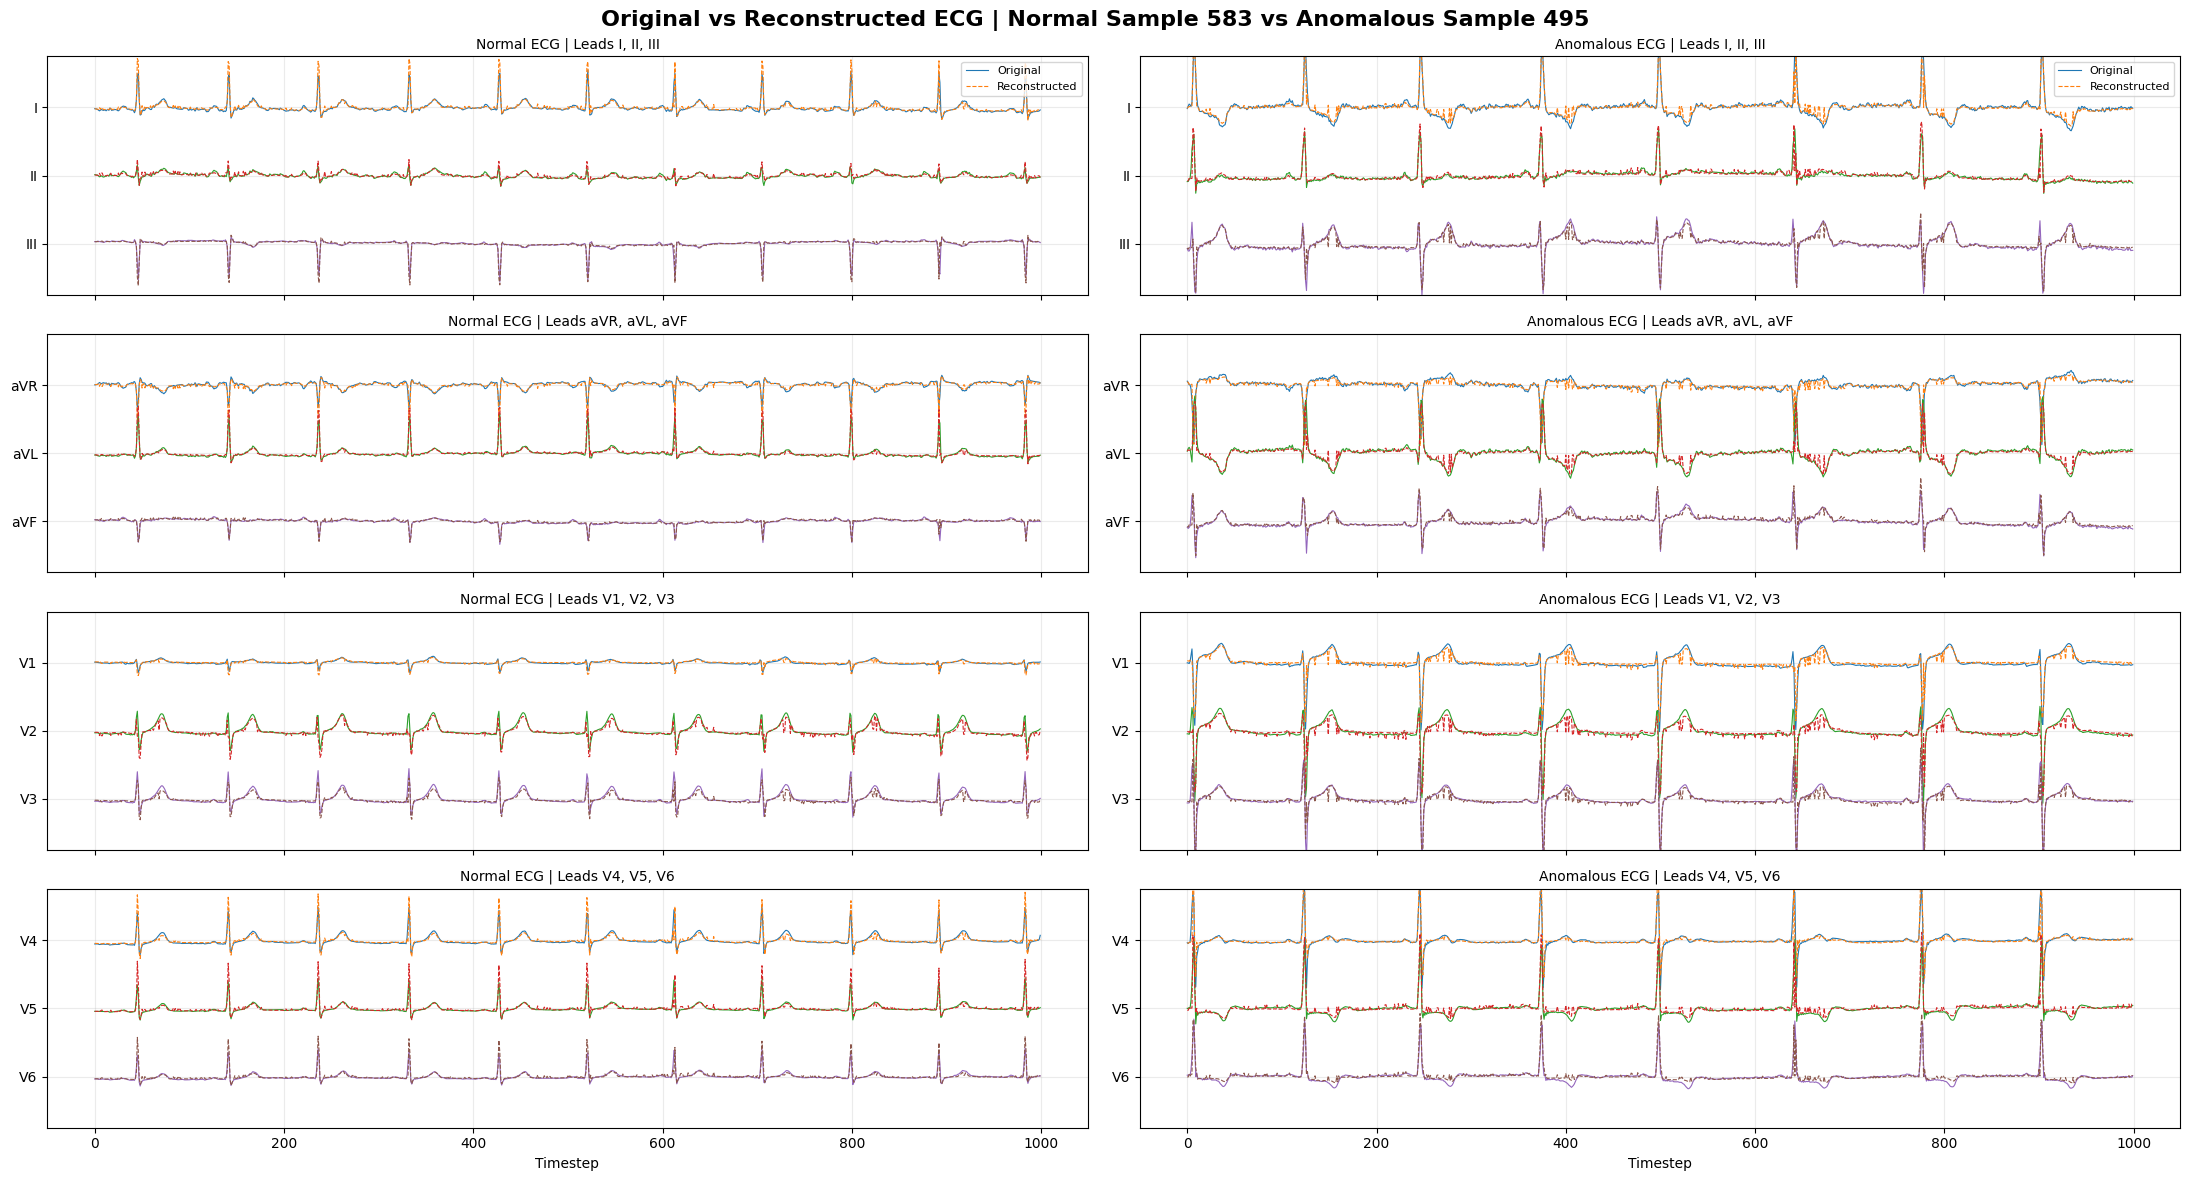

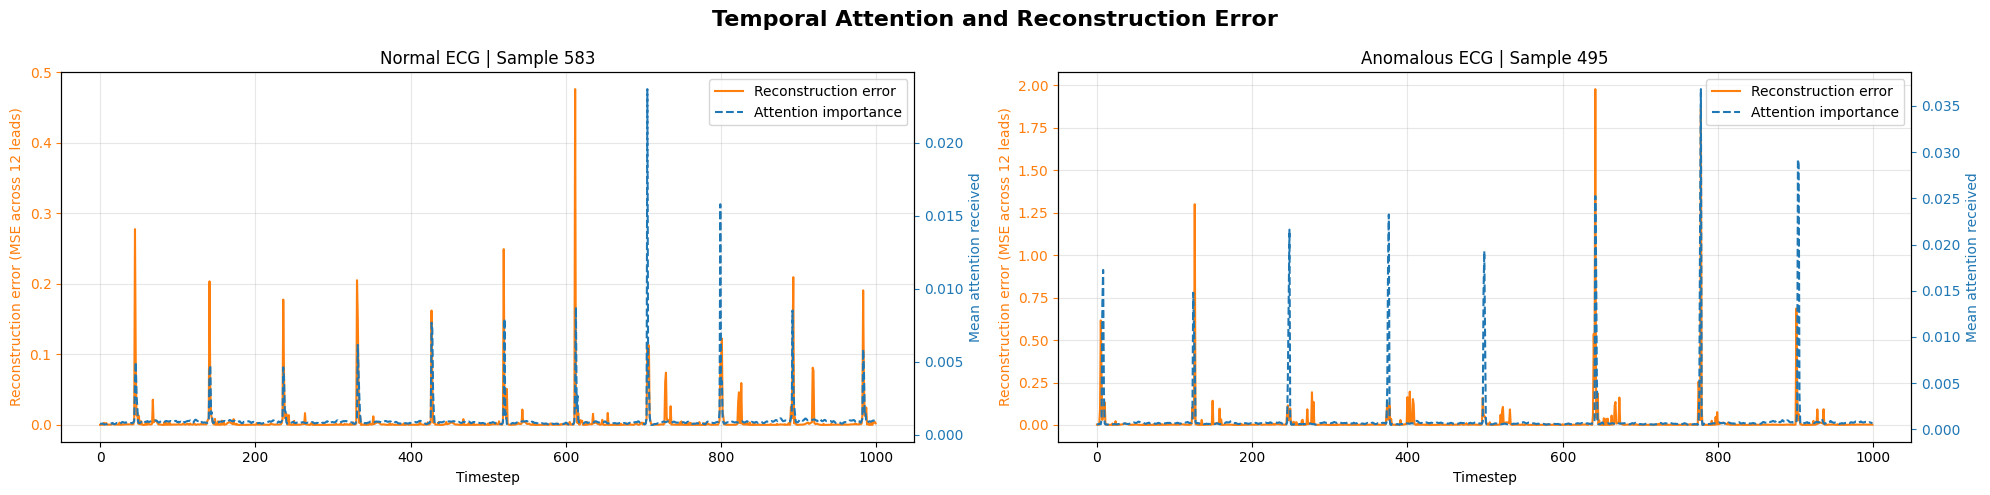

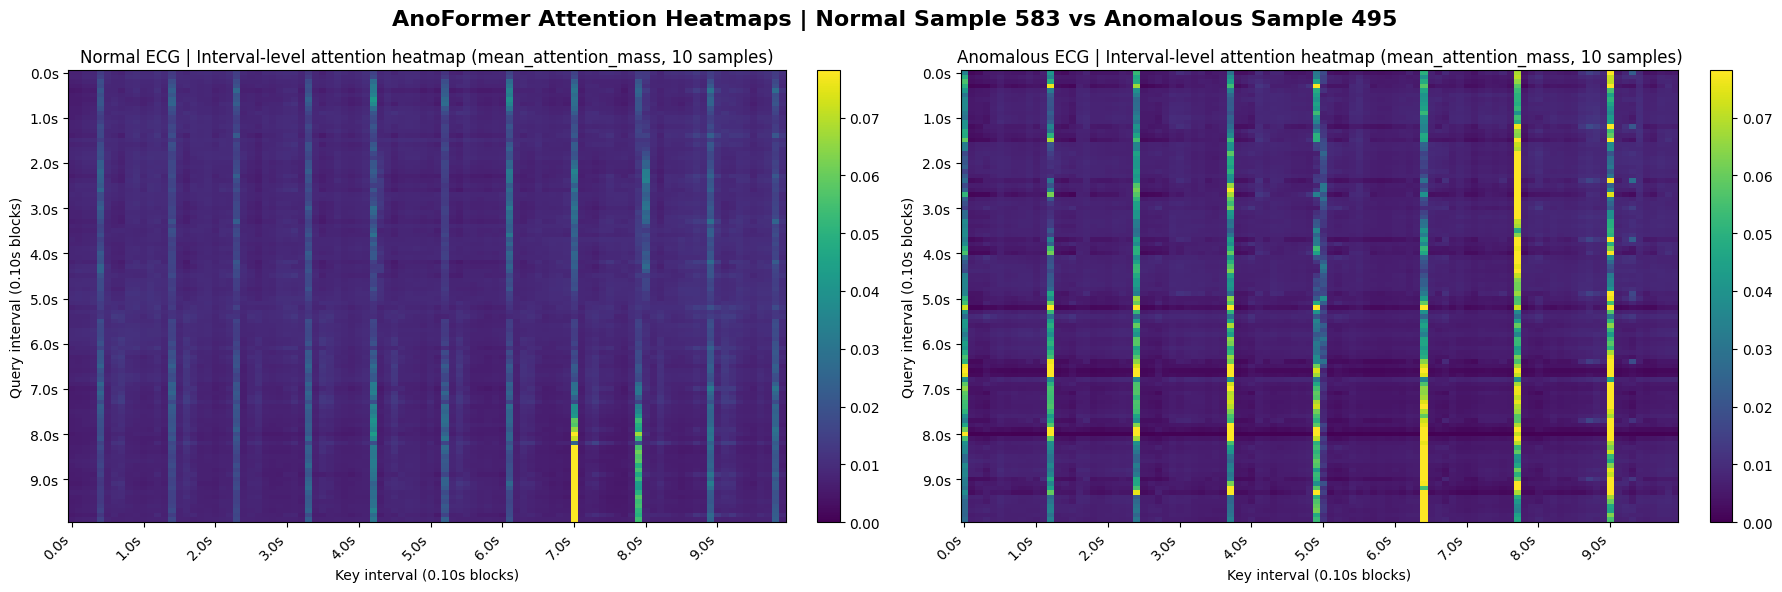

In [16]:
# AnoFormer Attention-based Explainability


print("\n── AnoFormer Attention-based Explainability ─────────────────────")

Explainer = AnoFormerExplainability(AnoFormer)


Explainer.CompareNormalAndAnomalousAttention(
    NormalWindow=NormalECG,
    AnomalousWindow=AnomalousECG,
    DatasetForInverseNorm=test_dataset,
    NormalIndex=NormalIndex,
    AnomalousIndex=AnomalousIndex,
    BlockIndex=0,
    HeadIndex=None,
    Percentile=99.0,
    UseIntervalHeatmap=True,
    BlockSize=10,
    Aggregation="mean_attention_mass",
    SamplingRate=100,
)

In [17]:
NormalTemporalAttention = (
    Explainer.GetIntervalAttentionImportance(
        TimeSeriesWindow=NormalECG,
        BlockIndex=0,
        HeadIndex=None,
        BlockSize=10,
    )
)

AnomalousTemporalAttention = (
    Explainer.GetIntervalAttentionImportance(
        TimeSeriesWindow=AnomalousECG,
        BlockIndex=0,
        HeadIndex=None,
        BlockSize=10,
    )
)

print("Normal:", NormalTemporalAttention.shape)
print("Anomalous:", AnomalousTemporalAttention.shape)

Normal: (100,)
Anomalous: (100,)


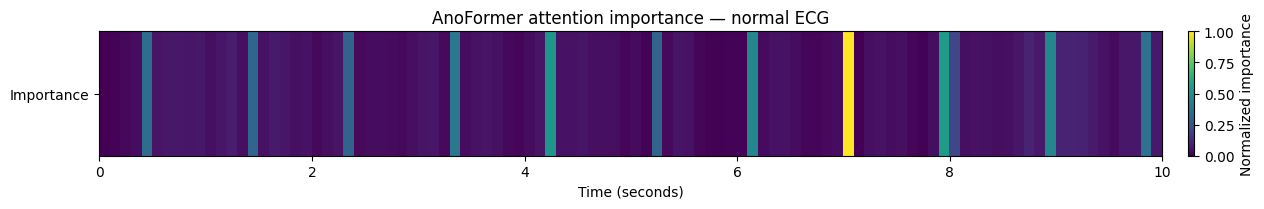

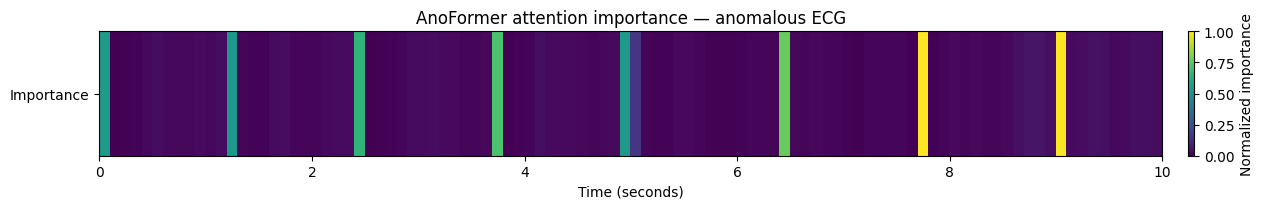

In [19]:
plot_temporal_importance(
    values=NormalTemporalAttention,
    title="AnoFormer attention importance — normal ECG",
    save_path=(
        RESULTS_DIR
        / "evaluation"
        / "anoformer_temporal_attention_normal.png"
    ),
)

plot_temporal_importance(
    values=AnomalousTemporalAttention,
    title="AnoFormer attention importance — anomalous ECG",
    save_path=(
        RESULTS_DIR
        / "evaluation"
        / "anoformer_temporal_attention_anomalous.png"
    ),
)

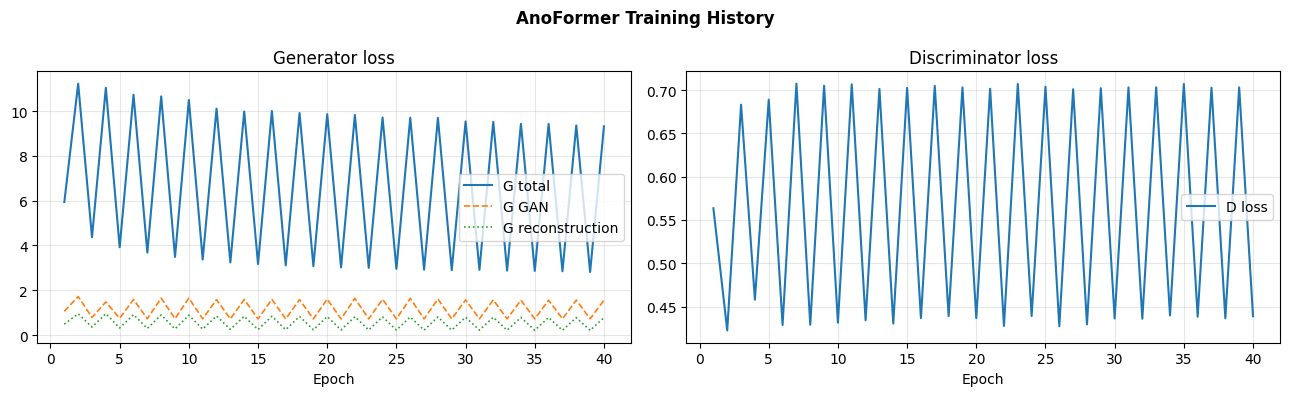

In [ ]:
# Show training loss

Explainer.ShowTrainingHistory()